# Notebook 5: Final Evaluation

## Import Libraries

In [94]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
)

## Load Saved Logits and Results

In [95]:
LOGIT_DIR = Path("./logits")
RESULT_DIR = Path("./results")
SPLIT_DIR = Path("./splits")
MODEL_DIR = Path("./models")

mobile_id = torch.load(
    LOGIT_DIR / "mobilenet_id_seed42.pt",
    map_location="cpu",
)

mobile_grape = torch.load(
    LOGIT_DIR / "mobilenet_grape_seed42.pt",
    map_location="cpu",
)

mobile_corn = torch.load(
    LOGIT_DIR / "mobilenet_corn_seed42.pt",
    map_location="cpu",
)

mobile_nonplant = torch.load(
    LOGIT_DIR / "mobilenet_nonplant_seed42.pt",
    map_location="cpu",
)

efficient_id = torch.load(
    LOGIT_DIR / "efficientnet_id_seed42.pt",
    map_location="cpu",
)

efficient_grape = torch.load(
    LOGIT_DIR / "efficientnet_grape_seed42.pt",
    map_location="cpu",
)

efficient_corn = torch.load(
    LOGIT_DIR / "efficientnet_corn_seed42.pt",
    map_location="cpu",
)

efficient_nonplant = torch.load(
    LOGIT_DIR / "efficientnet_nonplant_seed42.pt",
    map_location="cpu",
)

posthoc_results = pd.read_csv(
    RESULT_DIR / "posthoc_ood_results_seed42.csv"
)

## Recreate the four confidence scores

In [96]:
def msp_score(logits):
    probs = torch.softmax(logits, dim=1)
    return probs.max(dim=1).values.numpy()


def entropy_score(logits):
    probs = torch.softmax(logits, dim=1)

    entropy = -torch.sum(
        probs * torch.log(probs.clamp_min(1e-12)),
        dim=1,
    )

    max_entropy = np.log(logits.shape[1])

    return (
        1 - entropy / max_entropy
    ).numpy()


def margin_score(logits):
    probs = torch.softmax(logits, dim=1)

    top2 = torch.topk(
        probs,
        k=2,
        dim=1,
    ).values

    return (
        top2[:, 0] - top2[:, 1]
    ).numpy()


def energy_score(logits, temperature=1.0):
    return (
        temperature
        * torch.logsumexp(
            logits / temperature,
            dim=1,
        )
    ).numpy()


score_functions = {
    "MSP": msp_score,
    "Entropy": entropy_score,
    "Margin": margin_score,
    "Energy": energy_score,
}

## Calibration and Reliability

In [97]:
def expected_calibration_error(
    logits,
    labels,
    n_bins=15,
):
    probs = torch.softmax(logits, dim=1)

    confidences, predictions = probs.max(dim=1)

    accuracies = predictions.eq(labels)

    bin_edges = torch.linspace(
        0,
        1,
        n_bins + 1,
    )

    ece = torch.tensor(0.0)

    reliability = []

    for i in range(n_bins):
        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        in_bin = (
            (confidences > lower)
            & (confidences <= upper)
        )

        prop = in_bin.float().mean()

        if prop > 0:
            bin_acc = accuracies[
                in_bin
            ].float().mean()

            bin_conf = confidences[
                in_bin
            ].mean()

            ece += (
                torch.abs(bin_conf - bin_acc)
                * prop
            )

            reliability.append({
                "confidence": float(bin_conf),
                "accuracy": float(bin_acc),
                "count": int(in_bin.sum()),
            })

    return float(ece), pd.DataFrame(reliability)

In [98]:
mobile_ece, mobile_reliability = (
    expected_calibration_error(
        mobile_id["logits"],
        mobile_id["labels"],
    )
)

efficient_ece, efficient_reliability = (
    expected_calibration_error(
        efficient_id["logits"],
        efficient_id["labels"],
    )
)

print(f"MobileNet ECE:    {mobile_ece:.4f}")
print(f"EfficientNet ECE: {efficient_ece:.4f}")

MobileNet ECE:    0.0021
EfficientNet ECE: 0.0015


In [99]:
def plot_reliability(df, model_name):

    plt.figure(figsize=(6, 6))

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration",
    )

    plt.plot(
        df["confidence"],
        df["accuracy"],
        marker="o",
        label=model_name,
    )

    plt.xlabel("Mean confidence")
    plt.ylabel("Empirical accuracy")

    plt.title(
        f"{model_name} reliability diagram"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

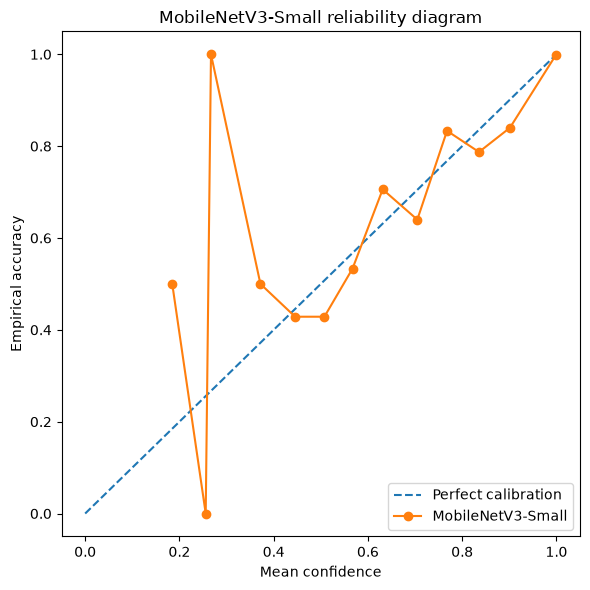

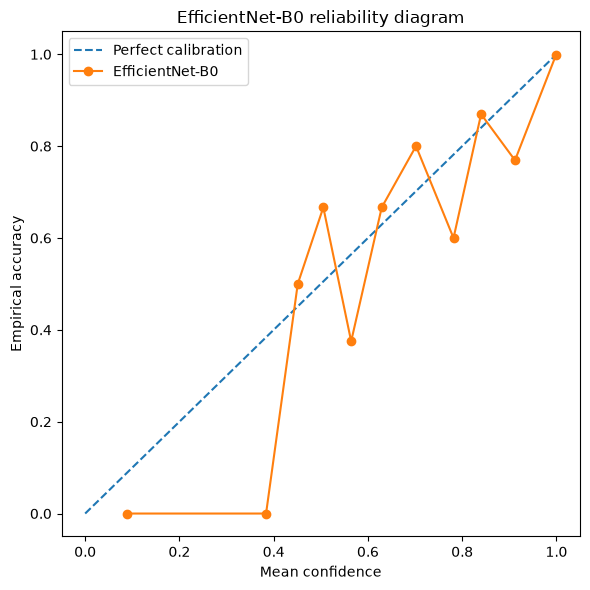

In [100]:
plot_reliability(
    mobile_reliability,
    "MobileNetV3-Small",
)

plot_reliability(
    efficient_reliability,
    "EfficientNet-B0",
)

## Risk-Coverage Curve

In [101]:
# Randomly select ID examples that match the combined OOD count because risk depends on the ID/OOD prevalance
SEED = 42

rng = np.random.default_rng(SEED)

n_ood = (
    len(mobile_grape["logits"])
    + len(mobile_corn["logits"])
    +  len(mobile_nonplant["logits"])
)

id_indices = rng.choice(
    len(mobile_id["logits"]),
    size=n_ood,
    replace=False,
)

len(id_indices)

8514

In [102]:
# MobileNet ID error labels
mobile_id_logits = mobile_id["logits"][
    id_indices
]

mobile_id_labels = mobile_id["labels"][
    id_indices
]

mobile_id_preds = mobile_id_logits.argmax(dim=1)

mobile_id_errors = (
    mobile_id_preds != mobile_id_labels
).numpy().astype(int)

In [103]:
# EfficientNet ID error labels
efficient_id_logits = efficient_id["logits"][
    id_indices
]

efficient_id_labels = efficient_id["labels"][
    id_indices
]

efficient_id_preds = efficient_id_logits.argmax(dim=1)

efficient_id_errors = (
    efficient_id_preds
    != efficient_id_labels
).numpy().astype(int)

In [104]:
# All OOD samples are errors if accepted
ood_errors = np.ones(
    n_ood,
    dtype=int,
)

For normal selective classification:

$$
\text{coverage} = \frac{\text{accepted samples}}{N}
$$

and:

$$
\text{risk} = \frac{\text{errors among accepted samples}}{\text{accepted samples}}
$$

For our research question, we need to extend the definition slightly.

For an ID image:
* **Correct ID prediction** $\rightarrow$ no error
* **Incorrect ID prediction** $\rightarrow$ error

For an OOD image:
* **If the model accepts it** $\rightarrow$ error


In [105]:
def risk_coverage_curve(
    id_scores,
    id_errors,
    ood_scores,
):
    scores = np.concatenate([
        id_scores,
        ood_scores,
    ])

    errors = np.concatenate([
        id_errors,
        np.ones(
            len(ood_scores),
            dtype=int,
        ),
    ])

    order = np.argsort(scores)[::-1]

    errors = errors[order]

    cumulative_errors = np.cumsum(errors)

    accepted = np.arange(
        1,
        len(errors) + 1,
    )

    coverage = accepted / len(errors)

    risk = cumulative_errors / accepted

    return coverage, risk

In [106]:
def aurc(coverage, risk):
    # Convert to numpy arrays
    coverage = np.asarray(coverage)
    risk = np.asarray(risk)
    
    # Sort both arrays based on ascending coverage
    sort_idx = np.argsort(coverage)
    
    return np.trapezoid(risk[sort_idx], coverage[sort_idx])

In [107]:
# Combine grape and corn logits
mobile_crop_ood_logits = torch.cat([
    mobile_grape["logits"],
    mobile_corn["logits"],
])

efficient_crop_ood_logits = torch.cat([
    efficient_grape["logits"],
    efficient_corn["logits"],
])

mobile_nonplant_logits = mobile_nonplant["logits"]
efficient_nonplant_logits = efficient_nonplant["logits"]

In [108]:
rc_results = []
rc_curves = {}

models = {
    "MobileNetV3-Small": {
        "id_logits": mobile_id_logits,
        "id_errors": mobile_id_errors,
        "crop_ood_logits": mobile_crop_ood_logits,
        "nonplant_logits": mobile_nonplant_logits,
    },

    "EfficientNet-B0": {
        "id_logits": efficient_id_logits,
        "id_errors": efficient_id_errors,
        "crop_ood_logits": efficient_crop_ood_logits,
        "nonplant_logits": efficient_nonplant_logits,
    },
}

In [109]:
for model_name, data in models.items():

    for method_name, score_fn in score_functions.items():

        id_scores = score_fn(
            data["id_logits"]
        )

        # Crop OOD
        crop_scores = score_fn(
            data["crop_ood_logits"]
        )

        coverage, risk = risk_coverage_curve(
            id_scores,
            data["id_errors"],
            crop_scores,
        )

        area = aurc(
            coverage,
            risk,
        )

        rc_curves[
            (model_name, method_name, "Crop")
        ] = (coverage, risk)

        rc_results.append({
            "model": model_name,
            "method": method_name,
            "ood_type": "Crop",
            "aurc": area,
        })

        # Non-plant OOD
        nonplant_scores = score_fn(
            data["nonplant_logits"]
        )

        coverage, risk = risk_coverage_curve(
            id_scores,
            data["id_errors"],
            nonplant_scores,
        )

        area = aurc(
            coverage,
            risk,
        )

        rc_curves[
            (model_name, method_name, "Nonplant")
        ] = (coverage, risk)

        rc_results.append({
            "model": model_name,
            "method": method_name,
            "ood_type": "Non-plant",
            "aurc": area,
        })

In [110]:
aurc_results = pd.DataFrame(
    rc_results
)

aurc_results

,model,method,ood_type,aurc
0,MobileNetV3-Small,MSP,Crop,0.153514
1,MobileNetV3-Small,MSP,Non-plant,0.004213
2,MobileNetV3-Small,Entropy,Crop,0.153016
3,MobileNetV3-Small,Entropy,Non-plant,0.004100
4,MobileNetV3-Small,Margin,Crop,0.154012
5,MobileNetV3-Small,Margin,Non-plant,0.004315
6,MobileNetV3-Small,Energy,Crop,0.160222
7,MobileNetV3-Small,Energy,Non-plant,0.004220
8,EfficientNet-B0,MSP,Crop,0.149320
9,EfficientNet-B0,MSP,Non-plant,0.002823


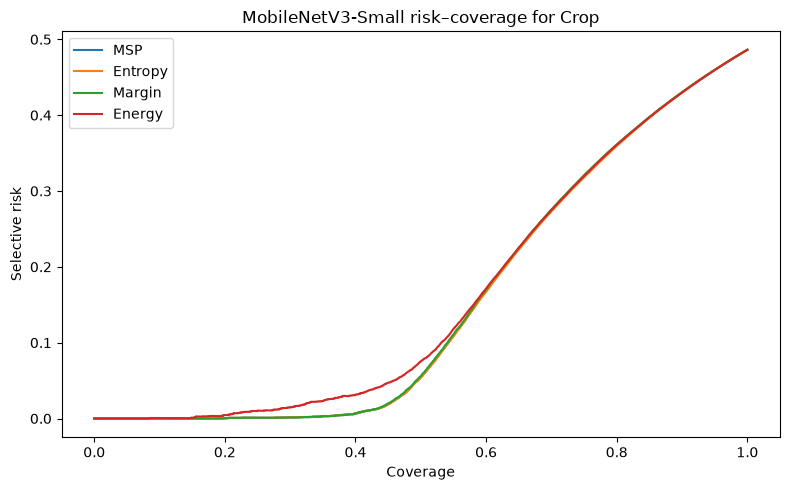

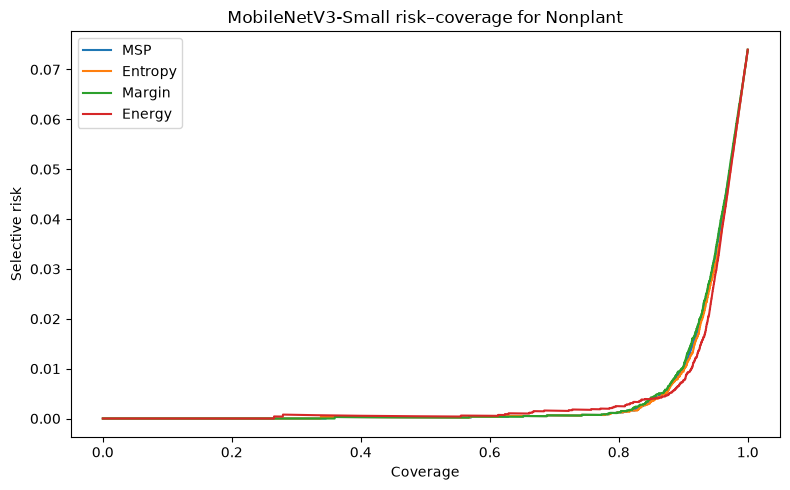

In [111]:
# MobileNet Risk-Coverage Curve
types = ["Crop", "Nonplant"]

for type in types:
    plt.figure(figsize=(8, 5))

    for method in score_functions:

        coverage, risk = rc_curves[
            ("MobileNetV3-Small", method, type)
        ]

        plt.plot(
            coverage,
            risk,
            label=method,
        )

    plt.xlabel("Coverage")
    plt.ylabel("Selective risk")

    plt.title(
        f'MobileNetV3-Small risk–coverage for {type}'
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

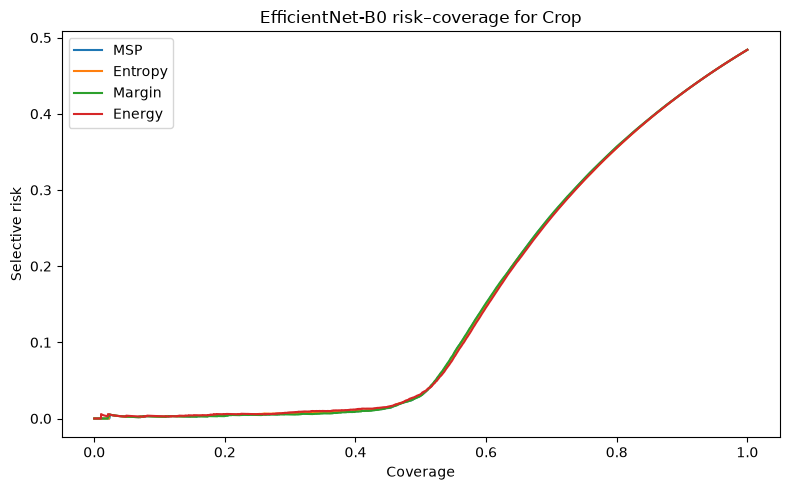

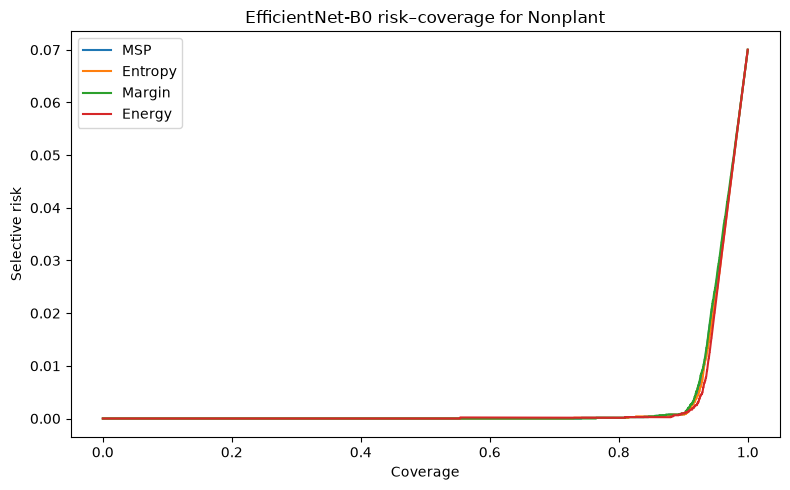

In [112]:
# EfficientNet Risk-Coverage Curve
types = ["Crop", "Nonplant"]

for type in types:
    plt.figure(figsize=(8, 5))

    for method in score_functions:

        coverage, risk = rc_curves[
            ("EfficientNet-B0", method, type)
        ]

        plt.plot(
            coverage,
            risk,
            label=method,
        )

    plt.xlabel("Coverage")
    plt.ylabel("Selective risk")

    plt.title(
        f'EfficientNet-B0 risk–coverage for {type}'
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

## Save Evaluation Results

In [113]:
aurc_results.to_csv(
    RESULT_DIR / "aurc_results_seed42.csv",
    index=False
)

calibration_results = pd.DataFrame([
    {
        "model": "MobileNetV3-Small",
        "ece": mobile_ece,
    },
    {
        "model": "EfficientNet-B0",
        "ece": efficient_ece,
    },
])

calibration_results.to_csv(
    RESULT_DIR / "calibration_results_seed42.csv",
    index=False
)